# Stage 3: default ya ocurrido y recuperaciones

## tl;dr
El motor histórico del 18-oct no distingue pérdida dado incumplimiento actual de nuevo default futuro. Esta auditoría separa PD y descuento. No es una calibración de cartera ni un cálculo contable aprobado.

## Context & Methods
### Key Assumptions
No POCI, gross=100 al cierre, sin undrawn/costos/curas, EIR original conocida, recuperaciones esperadas netas no negativas. Se compara el mismo LGD ya descontado. Referencia B5.5.33 en copia pública oficial adoptada2016; no afirmación de revisión normativa2026.

In [1]:
import json
from pathlib import Path
from src.model import shortfall, scenario_shortfall
example=json.loads(Path('results/example.json').read_text())
print(example)
assert abs(example['cash_shortfall']-(100-60/1.1**2))<1e-12
assert example['tiny_rate_stable']>0 and example['tiny_rate_subtractive']==0

{'gross': 100, 'recovery': 60, 'recovery_lag': 2, 'eir': 0.1, 'pd12': 0.05, 'future_pd_horizon': 5, 'cash_shortfall': 50.413223140495866, 'baseline_ecl': 10.21191964736598, 'certainty_but_extra_discount': 45.83020285499624, 'scenario_ecl': 47.10743801652893, 'tiny_rate_stable': 1.0000000000000001e-16, 'tiny_rate_subtractive': 0.0}


## Data
432 casos del producto cartesiano en results/config.json, sin muestreo selectivo. Se mantiene constante el estado incumplido y se varía la PD ajena a ese estado. Las columnas de ablación eliminan sólo uno de los dos factores espurios.

In [2]:
import pandas as pd
from IPython.display import display
rows=pd.read_csv('results/accuracy.csv')
summary=json.loads(Path('results/summary.json').read_text())
print({k:summary[k] for k in ['cases','nonzero_reference_cases','baseline_underestimates','oracle_max_relative_error']})
assert summary['oracle_max_relative_error']<=1e-12
display(rows[['pd12','eir','horizon','baseline_ecl','cash_shortfall']].head(6))

{'cases': 432, 'nonzero_reference_cases': 372, 'baseline_underestimates': 372, 'oracle_max_relative_error': 1.3230795769326005e-16}


,pd12,eir,horizon,baseline_ecl,cash_shortfall
0,0.01,0.0,1,0.800000,80.0
1,0.01,0.0,5,4.761104,80.0
2,0.01,0.0,10,11.840526,80.0
3,0.01,0.1,1,0.727273,80.0
4,0.01,0.1,5,3.553071,80.0
5,0.01,0.1,10,6.838167,80.0


## Results
Figura sobre casos fijados, no intervalo de confianza.

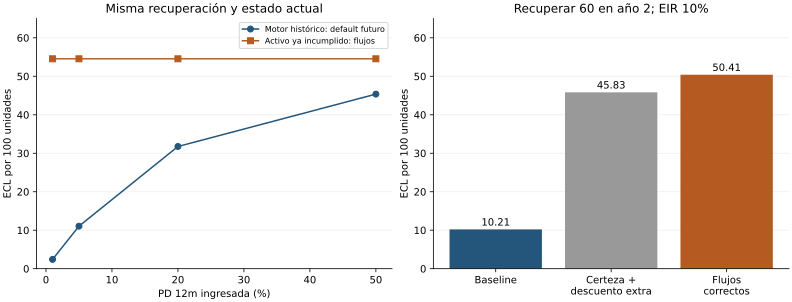

In [3]:
from IPython.display import SVG
display(SVG(filename='results/comparison.svg'))

## Takeaways
No se debe reutilizar sin adaptación una curva de nuevo default para un activo ya incumplido. Una LGD a valor presente tampoco se vuelve a descontar por defecto. Esta sección reproduce el snapshot histórico; la reconciliación posterior audita el padre actual. No todos los Stage3 son reducibles a este caso; no se modela POCI, cura, write-off, intereses ni error de estimación de recuperaciones. Referencias y crítica en informe.md.

## Migración reconciliada — 2026-10-19

El motor padre YA aplica flujos Stage3. El baseline histórico se congela en baselines/ con hash verificado para no confundir versiones. Se prueban 432 casos Stage3 y 300 contratos mixtos, comparando por loan_id. La equivalencia Stage1/2 excluye cambios de caps y clipping de PD original.

{'stage3_cases': 432, 'stage3_max_relative_error': 1.3230795769326005e-16, 'mixed_loans': 300, 'stage12_max_relative_change': 9.084315339071267e-16, 'tiny_rate_subtractive': 0.0, 'tiny_rate_current': 1.0000000000000001e-16}


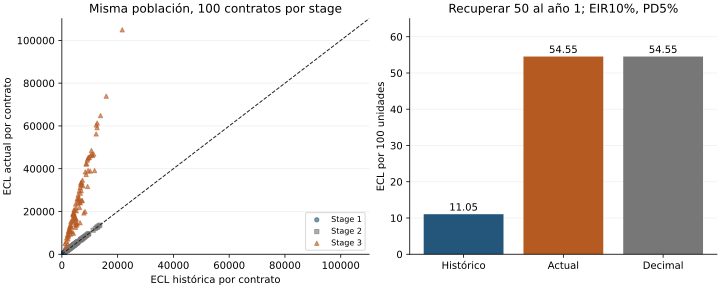

In [4]:
migration=json.loads(Path('results/migration-summary.json').read_text())
keys=['stage3_cases','stage3_max_relative_error','mixed_loans','stage12_max_relative_change','tiny_rate_subtractive','tiny_rate_current']
print({k:migration[k] for k in keys})
assert migration['stage3_max_relative_error']<1e-12
assert migration['stage12_max_relative_change']<1e-12
display(SVG(filename='results/migration.svg'))

### Límite de la reconciliación
El snapshot no estima pérdidas reales ni certifica IFRS9. Se conserva prechange-reproduction.txt con el fallo previo; diferencias fuera del dominio compartido requieren revisión, no se declaran idénticas. La ruta actual por contrato tiene mayor coste que el cálculo vectorizado.